# Weighing the Invisible: Estimating the Mass of Sagittarius A* Through Comparative Analysis of Stellar Orbits

**Astrophysics data-analysis project**

## Research question
Can the observed motion of S2, together with published orbital parameters for other stars near the Galactic Centre, help estimate the mass of the central object Sagittarius A*?

## Abstract
Sagittarius A* is associated with a supermassive black hole at the centre of the Milky Way. Its mass can be inferred from the gravitational influence it has on nearby stars. This project analyses astrometric positions and radial-velocity measurements of S2, fits a descriptive ellipse to its projected sky trajectory, and estimates the central mass using Kepler's third law. It then compares the estimate with calculations based on published orbital parameters for S1, S8, S12, S13, and S14.

The comparison uses literature values rather than raw observations for the additional stars. It is a comparative consistency check, not a fresh orbit fit for every star. Assumptions and limitations are identified explicitly.

## 1. Objectives
1. Load and inspect the supplied S2 astrometry and radial-velocity datasets.
2. Visualise S2's projected sky positions and line-of-sight velocity.
3. Fit a descriptive ellipse to S2's observed sky positions.
4. Estimate the central mass using Kepler's third law.
5. Compare mass estimates calculated from published orbital parameters for several Galactic-centre stars.
6. Discuss assumptions, uncertainty, and limitations.

## 2. Scientific background
**Astrometry** measures a star's position on the sky. **Radial velocity** measures the component of its velocity along our line of sight. Combining them helps astronomers reconstruct stellar orbits.

For a star orbiting a much more massive central object, Kepler's third law gives

\[
M \simeq \frac{4\pi^2a^3}{GP^2},
\]

where \(M\) is central mass, \(a\) is physical semi-major axis, \(P\) is orbital period, and \(G\) is the gravitational constant. When \(a\) is in AU and \(P\) in years,

\[
\frac{M}{M_\odot} \simeq \frac{a^3(\mathrm{AU})}{P^2(\mathrm{yr})}.
\]

For angular semi-major axis \(\alpha\) in arcseconds and distance \(D\) in parsecs,

\[
a(\mathrm{AU}) \simeq \alpha(\mathrm{arcsec})D(\mathrm{pc}).
\]

This assumes the central mass dominates each orbit and all stars orbit the same central object.

## 3. Import libraries
We use `pandas` to read CSV files, `numpy` for calculations, `matplotlib` for plots, and `scipy` for a descriptive ellipse fit. Keep all five CSV files in the same folder as this notebook.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from IPython.display import display

plt.rcParams["figure.figsize"] = (8, 5)

## 4. Load S2 observations
The supplied data include NACO and SHARP astrometry and radial velocities from NACO, OSIRIS, and SINFONI. Instrument labels are retained for plotting.

In [3]:
required_files = ["astrometry_NACO.csv", "astrometry_SHARP.csv",
                  "velocity_NACO.csv", "velocity_OSIRIS.csv", "velocity_SINFONI.csv"]
missing = [f for f in required_files if not os.path.exists(f)]
if missing:
    raise FileNotFoundError("CSV files not found: " + ", ".join(missing)
                            + ". Move them into the notebook folder or update the paths.")

ast_naco = pd.read_csv("astrometry_NACO.csv")
ast_sharp = pd.read_csv("astrometry_SHARP.csv")
ast_naco["instrument"] = "NACO"
ast_sharp["instrument"] = "SHARP"
astrometry = pd.concat([ast_naco, ast_sharp], ignore_index=True)

velocity_parts = []
for filename, instrument in [
    ("velocity_NACO.csv", "NACO"),
    ("velocity_OSIRIS.csv", "OSIRIS"),
    ("velocity_SINFONI.csv", "SINFONI")
]:
    frame = pd.read_csv(filename)
    frame["instrument"] = instrument
    velocity_parts.append(frame)
velocity = pd.concat(velocity_parts, ignore_index=True).sort_values("t").reset_index(drop=True)

print("NACO astrometry:", len(ast_naco))
print("SHARP astrometry:", len(ast_sharp))
print("Total astrometry:", len(astrometry))
print("Radial-velocity observations:", len(velocity))
print("Astrometry columns:", astrometry.columns.tolist())
print("Velocity columns:", velocity.columns.tolist())

NACO astrometry: 133
SHARP astrometry: 12
Total astrometry: 145
Radial-velocity observations: 44
Astrometry columns: ['t', 'x', 'x_err', 'y', 'y_err', 'instrument']
Velocity columns: ['t', 'vz', 'vz_err', 'instrument']


## 5. Inspect the data
Check first rows, missing values, and numerical ranges before plotting. The time column is decimal year. Confirm position and velocity units against the original dataset documentation before interpreting the axes physically.

In [4]:
display(astrometry.head())
display(velocity.head())
print("Missing astrometry values:")
display(astrometry.isna().sum())
print("Missing velocity values:")
display(velocity.isna().sum())
print("Astrometry summary:")
display(astrometry[["t", "x", "x_err", "y", "y_err"]].describe())
print("Radial-velocity summary:")
display(velocity[["t", "vz", "vz_err"]].describe())

,t,x,x_err,y,y_err,instrument
0,2002.2503,0.008122,0.002810,-0.014417,0.002810,NACO
1,2002.3351,-0.003988,0.001887,-0.009717,0.001887,NACO
2,2002.3927,-0.013654,0.002662,-0.002115,0.002662,NACO
3,2002.4085,-0.015542,0.002303,-0.000060,0.002303,NACO
4,2002.4115,-0.014656,0.002303,0.000165,0.002303,NACO


,t,vz,vz_err,instrument
0,2000.4870,1199.0,100.0,OSIRIS
1,2002.4175,-495.0,36.0,OSIRIS
2,2002.4205,-532.0,44.0,OSIRIS
3,2003.2711,-1571.0,52.0,SINFONI
4,2003.3532,-1512.0,35.0,NACO


Missing astrometry values:


t             0
x             0
x_err         0
y             0
y_err         0
instrument    0
dtype: int64

Missing velocity values:


t             0
vz            0
vz_err        0
instrument    0
dtype: int64

Astrometry summary:


,t,x,x_err,y,y_err
count,145.000000,145.000000,145.000000,145.000000,145.000000
mean,2008.053473,0.017899,0.000675,0.134147,0.000653
std,4.966185,0.035498,0.001021,0.051147,0.000969
min,1992.224100,-0.039112,0.000216,-0.014417,0.000215
25%,2004.442700,-0.022951,0.000234,0.111130,0.000234
50%,2009.335500,0.028958,0.000268,0.155556,0.000268
75%,2011.552800,0.048019,0.000422,0.175088,0.000421
max,2016.530200,0.071202,0.007938,0.179550,0.007436


Radial-velocity summary:


,t,vz,vz_err
count,44.000000,44.000000,44.000000
mean,2008.748550,-264.159091,41.068182
std,4.439339,729.854173,15.564416
min,2000.487000,-1571.000000,15.000000
25%,2005.214400,-844.250000,30.000000
50%,2007.611350,-453.500000,40.000000
75%,2012.561225,224.500000,50.000000
max,2016.519100,1199.000000,100.000000


## 6. Visualise S2's observed sky positions
This is the two-dimensional projection of S2's position on the sky, not its complete three-dimensional orbit.

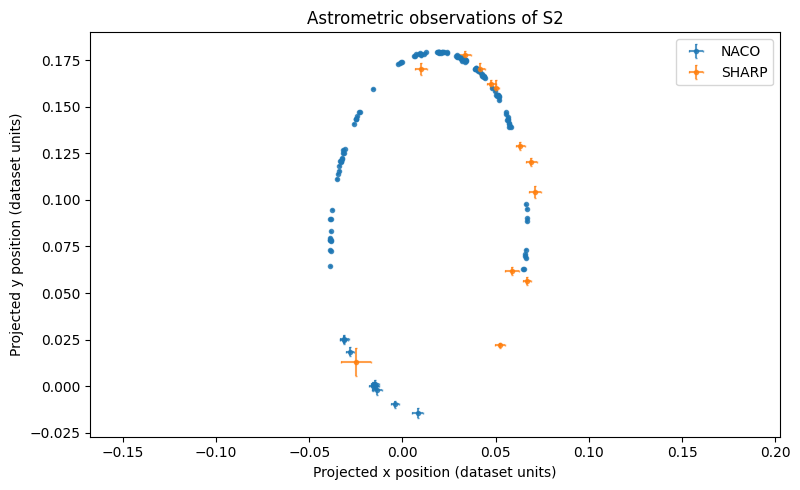

In [5]:
plt.figure()
for instrument, group in astrometry.groupby("instrument"):
    plt.errorbar(group["x"], group["y"], xerr=group["x_err"], yerr=group["y_err"],
                 fmt="o", markersize=3, capsize=1, alpha=0.75, label=instrument)
plt.xlabel("Projected x position (dataset units)")
plt.ylabel("Projected y position (dataset units)")
plt.title("Astrometric observations of S2")
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Visualise S2's radial velocity
Radial velocity describes motion towards or away from the observer. Its variation over time gives complementary information about the orbit.

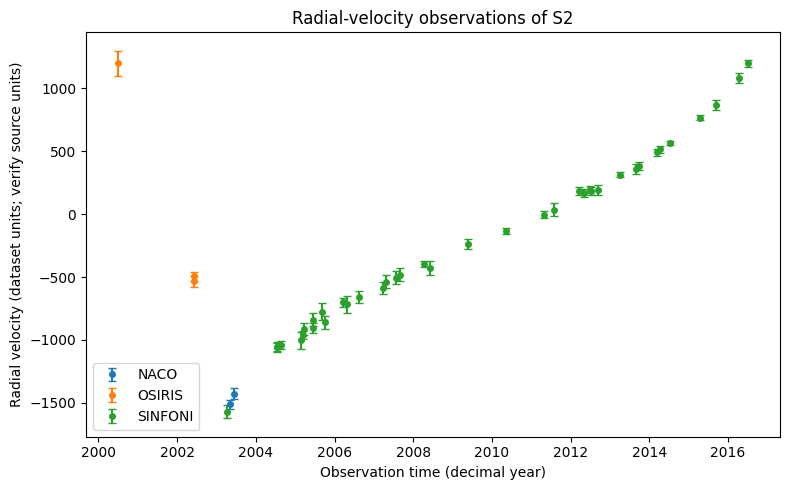

In [6]:
plt.figure()
for instrument, group in velocity.groupby("instrument"):
    plt.errorbar(group["t"], group["vz"], yerr=group["vz_err"],
                 fmt="o", capsize=3, markersize=4, label=instrument)
plt.xlabel("Observation time (decimal year)")
plt.ylabel("Radial velocity (dataset units; verify source units)")
plt.title("Radial-velocity observations of S2")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Fit a descriptive ellipse to S2's projected positions
This geometric fit uses positions only. It does not fit the time evolution, radial velocities, or measurement uncertainties; treat it as a visual description rather than a precision orbital solution.

In [7]:
x = astrometry["x"].to_numpy(dtype=float)
y = astrometry["y"].to_numpy(dtype=float)
valid = np.isfinite(x) & np.isfinite(y)
x, y = x[valid], y[valid]

def ellipse_residuals(p, x, y):
    x0, y0, log_a, log_b, theta = p
    a, b = np.exp(log_a), np.exp(log_b)
    ct, st = np.cos(theta), np.sin(theta)
    dx, dy = x - x0, y - y0
    xp, yp = ct*dx + st*dy, -st*dx + ct*dy
    return (xp/a)**2 + (yp/b)**2 - 1

p0 = [np.mean(x), np.mean(y), np.log(np.ptp(x)/2), np.log(np.ptp(y)/2), 0.0]
fit = least_squares(ellipse_residuals, p0, args=(x, y), max_nfev=20000)
x0_fit, y0_fit, log_a_fit, log_b_fit, theta_fit = fit.x
a_fit, b_fit = np.exp(log_a_fit), np.exp(log_b_fit)
print(f"Ellipse centre: ({x0_fit:.6g}, {y0_fit:.6g}) dataset units")
print(f"Fitted axis lengths: {a_fit:.6g}, {b_fit:.6g} dataset units")
print(f"Rotation parameter: {np.degrees(theta_fit):.2f} degrees")
print("Fit successful:", fit.success)

Ellipse centre: (0.0141266, 0.0829004) dataset units
Fitted axis lengths: 0.0528633, 0.0964122 dataset units
Rotation parameter: -3.02 degrees
Fit successful: True


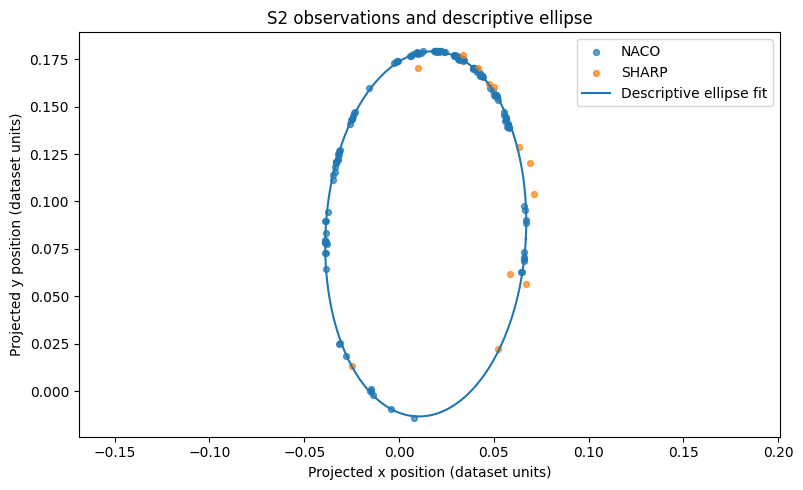

In [8]:
ct, st = np.cos(theta_fit), np.sin(theta_fit)
phi = np.linspace(0, 2*np.pi, 600)
xe_local, ye_local = a_fit*np.cos(phi), b_fit*np.sin(phi)
xe = x0_fit + ct*xe_local - st*ye_local
ye = y0_fit + st*xe_local + ct*ye_local
plt.figure()
for instrument, group in astrometry.groupby("instrument"):
    plt.scatter(group["x"], group["y"], s=18, alpha=0.7, label=instrument)
plt.plot(xe, ye, label="Descriptive ellipse fit")
plt.xlabel("Projected x position (dataset units)")
plt.ylabel("Projected y position (dataset units)")
plt.title("S2 observations and descriptive ellipse")
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Estimate the mass using S2
For this transparent Kepler-law calculation, we adopt approximate published parameters for S2: angular semi-major axis \(0.1226\) arcsec and period \(15.24\) years, with Galactic-centre distance \(8200\) parsecs. These values come from a published global fit; they are **not** derived from the descriptive ellipse above.

We calculate \(a(\mathrm{AU})=\alpha D\), then \(M/M_\odot=a^3/P^2\). The result is approximate and depends on the adopted distance and orbital parameters.

In [9]:
distance_pc = 8200.0
s2_alpha_arcsec = 0.1226
s2_period_years = 15.24
s2_a_AU = s2_alpha_arcsec * distance_pc
s2_mass_solar = s2_a_AU**3 / s2_period_years**2

print(f"S2 physical semi-major axis: {s2_a_AU:.1f} AU")
print(f"S2 orbital period: {s2_period_years:.2f} years")
print(f"S2-based mass estimate: {s2_mass_solar:,.0f} solar masses")
print(f"S2-based mass estimate: {s2_mass_solar/1e6:.3f} million solar masses")

S2 physical semi-major axis: 1005.3 AU
S2 orbital period: 15.24 years
S2-based mass estimate: 4,374,647 solar masses
S2-based mass estimate: 4.375 million solar masses


## 10. Compare S2 with other Galactic-centre stars
This section uses **published orbital parameters**, not raw observations, for S1, S8, S12, S13, and S14. The angular semi-major axes, eccentricities, and periods are from Eisenhauer et al. (2005), Table 2. We use the same adopted distance of 8200 pc for all stars. This is a literature-data comparison, not a new orbit fit for each star.

In [10]:
# Published orbital parameters from Eisenhauer et al. (2005), Table 2.
comparison = pd.DataFrame([
    {"star": "S1",  "a_arcsec": 0.4120, "e": 0.358, "P_years": 94.1},
    {"star": "S2",  "a_arcsec": 0.1226, "e": 0.876, "P_years": 15.24},
    {"star": "S8",  "a_arcsec": 0.3290, "e": 0.927, "P_years": 67.2},
    {"star": "S12", "a_arcsec": 0.2860, "e": 0.902, "P_years": 54.4},
    {"star": "S13", "a_arcsec": 0.2190, "e": 0.395, "P_years": 36.0},
    {"star": "S14", "a_arcsec": 0.2250, "e": 0.939, "P_years": 38.0},
])
comparison["a_AU"] = comparison["a_arcsec"] * distance_pc
comparison["mass_solar"] = comparison["a_AU"]**3 / comparison["P_years"]**2
comparison["mass_million_solar"] = comparison["mass_solar"] / 1e6
display(comparison.round({"a_arcsec": 4, "e": 3, "P_years": 2, "a_AU": 1,
                          "mass_solar": 0, "mass_million_solar": 3}))

,star,a_arcsec,e,P_years,a_AU,mass_solar,mass_million_solar
0,S1,0.4120,0.358,94.10,3378.4,4354657.0,4.355
1,S2,0.1226,0.876,15.24,1005.3,4374647.0,4.375
2,S8,0.3290,0.927,67.20,2697.8,4348012.0,4.348
3,S12,0.2860,0.902,54.40,2345.2,4358548.0,4.359
4,S13,0.2190,0.395,36.00,1795.8,4468573.0,4.469
5,S14,0.2250,0.939,38.00,1845.0,4349326.0,4.349


### 10.1 Compare inferred central masses
If the published orbital parameters are mutually consistent, the estimates should be broadly similar. Differences can arise from measurement uncertainties, the particular historical orbit fit, and the assumed Galactic-centre distance.

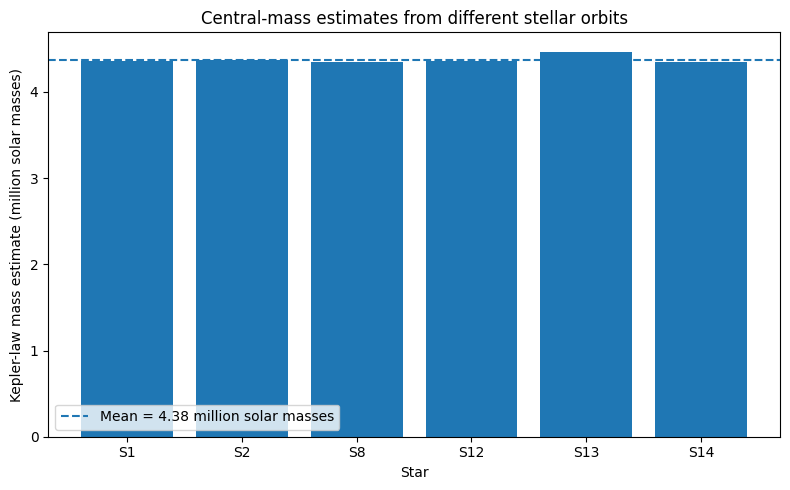

Mean estimate: 4.376 million solar masses
Standard deviation: 0.047 million solar masses
Range: 4.348 to 4.469 million solar masses


In [11]:
plt.figure()
plt.bar(comparison["star"], comparison["mass_million_solar"])
mean_mass = comparison["mass_million_solar"].mean()
plt.axhline(mean_mass, linestyle="--", label=f"Mean = {mean_mass:.2f} million solar masses")
plt.ylabel("Kepler-law mass estimate (million solar masses)")
plt.xlabel("Star")
plt.title("Central-mass estimates from different stellar orbits")
plt.legend()
plt.tight_layout()
plt.show()
print("Mean estimate:", round(mean_mass, 3), "million solar masses")
print("Standard deviation:", round(comparison["mass_million_solar"].std(ddof=1), 3), "million solar masses")
print("Range:", round(comparison["mass_million_solar"].min(), 3), "to",
      round(comparison["mass_million_solar"].max(), 3), "million solar masses")

### 10.2 Compare orbital periods and eccentricities
Orbital period is the time needed to complete an orbit. Eccentricity describes how elongated the orbit is: zero is circular, while values closer to one are more elongated.

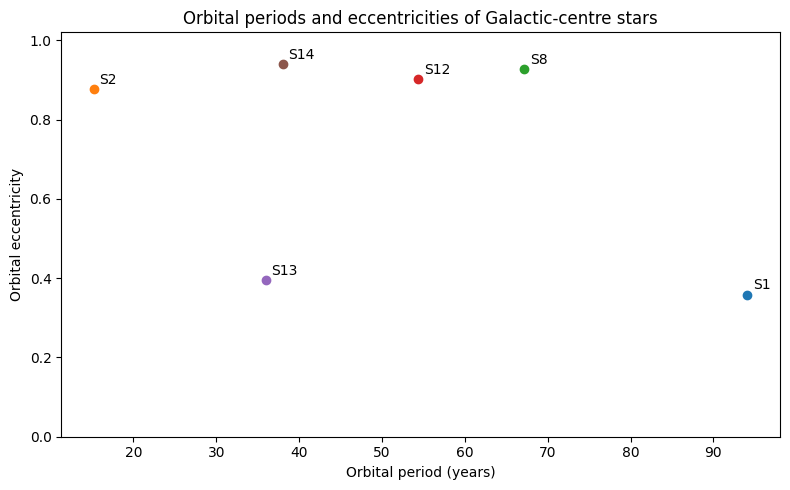

In [12]:
plt.figure()
for _, row in comparison.iterrows():
    plt.scatter(row["P_years"], row["e"])
    plt.annotate(row["star"], (row["P_years"], row["e"]), xytext=(4, 4),
                 textcoords="offset points")
plt.xlabel("Orbital period (years)")
plt.ylabel("Orbital eccentricity")
plt.title("Orbital periods and eccentricities of Galactic-centre stars")
plt.ylim(0, 1.02)
plt.tight_layout()
plt.show()

## 11. Residuals from a constant-velocity baseline
A proper orbital residual analysis requires predicted velocities from a fitted Keplerian orbit. Because this notebook does not fit a complete time-dependent orbit, the following is only a baseline diagnostic, **not** an orbital-model residual analysis.

Weighted mean velocity: -18.85 (dataset units)
Baseline chi-square: 18052.52
Degrees of freedom: 43
Reduced chi-square: 419.83


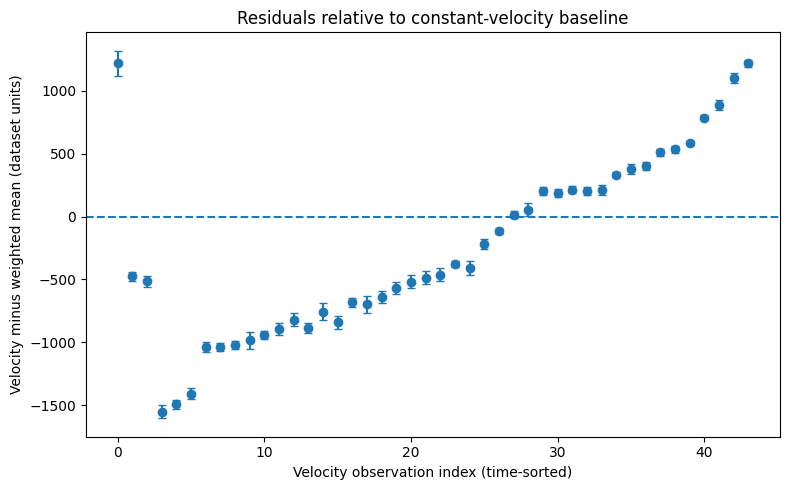

In [13]:
v = velocity["vz"].to_numpy(dtype=float)
ve = velocity["vz_err"].to_numpy(dtype=float)
ok = np.isfinite(v) & np.isfinite(ve) & (ve > 0)
v, ve = v[ok], ve[ok]
weights = 1 / ve**2
weighted_mean = np.sum(weights*v) / np.sum(weights)
residuals = v - weighted_mean
chi2 = np.sum((residuals/ve)**2)
print(f"Weighted mean velocity: {weighted_mean:.2f} (dataset units)")
print(f"Baseline chi-square: {chi2:.2f}")
print(f"Degrees of freedom: {len(v)-1}")
print(f"Reduced chi-square: {chi2/(len(v)-1):.2f}")
plt.figure()
plt.errorbar(np.arange(len(v)), residuals, yerr=ve, fmt="o", capsize=3)
plt.axhline(0, linestyle="--")
plt.xlabel("Velocity observation index (time-sorted)")
plt.ylabel("Velocity minus weighted mean (dataset units)")
plt.title("Residuals relative to constant-velocity baseline")
plt.tight_layout()
plt.show()

## 12. Discussion

### Main findings
- S2's astrometry traces its changing projected position around Sagittarius A*.
- Its radial velocity changes substantially with time, providing complementary evidence of orbital motion.
- Kepler's third law connects orbital size and period to the mass of the central object.
- Applying the same simplified calculation to published parameters for six stars allows a consistency comparison.
- The stars have different periods and eccentricities, but their orbital parameters describe motion around the same central gravitational source.

### Limitations
1. The ellipse fitted to S2 is geometric, not a full time-dependent Keplerian orbit fit.
2. The S2 mass calculation uses published orbital parameters, not the fitted ellipse.
3. The comparison stars' raw observations are not fitted here; their parameters are taken from a published paper.
4. The distance is assumed to be 8200 pc, and uncertainties are not propagated.
5. Relativistic effects, extended mass, correlated astrometric noise, and instrument systematics are not modelled.
6. The constant-velocity residual plot is a baseline diagnostic, not a residual plot from an orbital model.

### Possible extensions
Fit the full Keplerian equations to each star's time-tagged astrometry and radial velocities, propagate uncertainties, and compare independently fitted mass estimates.

## 13. Conclusion

This project demonstrates how the motion of stars can reveal the mass of an invisible central object. S2 is the main observational case study, using sky positions and radial velocities. A comparative calculation using published orbital parameters for S1, S8, S12, S13, and S14 broadens the investigation and tests whether different stellar orbits give broadly consistent mass estimates.

The result is an assumption-dependent comparison, not a precision determination of the mass of Sagittarius A*. A full dynamical fit with uncertainty analysis would be required for a rigorous measurement.

## 14. References

1. Eisenhauer, F., et al. (2005). *SINFONI in the Galactic Center: Young stars and infrared flares in the central light-month*. The Astrophysical Journal, 628, 246–259. https://doi.org/10.1086/430667. Source for the historical orbital parameters in the comparison table.
2. Plewa, P. M., et al. *GC-OrbitFit: orbit fitting for Galactic-centre stars*. Repository and documentation: https://github.com/pmplewa/GC-OrbitFit. Source for the supplied S2 dataset and an advanced fitting approach.
3. European Southern Observatory (ESO). Public information on the Galactic Centre and stars orbiting Sagittarius A*: https://www.eso.org/public/

